# 05 Modelling

This notebook corresponds to the **Machine Learning Modelling** stage.

Goals:
- Predict station imbalance 30 minutes ahead for Dublin Bikes

In [15]:
import torch
import time


print("torch:", torch.__version__)
print("cuda runtime:", torch.version.cuda)
print("cuda available:", torch.cuda.is_available())
print("archs:", torch.cuda.get_arch_list())

if torch.cuda.is_available():
    print("gpu:", torch.cuda.get_device_name(0))


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

x = torch.rand(3000, 3000, device=device)
y = torch.rand(3000, 3000, device=device)

torch.cuda.synchronize()
t0 = time.time()
z = x @ y
torch.cuda.synchronize()
t1 = time.time()

print("Result device:", z.device)
print("Elapsed:", t1 - t0, "seconds")

RANDOM_SEED = 42
torch.manual_seed(RANDOM_SEED) 
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, f1_score

torch: 2.10.0+cu128
cuda runtime: 12.8
cuda available: True
archs: ['sm_70', 'sm_75', 'sm_80', 'sm_86', 'sm_90', 'sm_100', 'sm_120']
gpu: NVIDIA GeForce RTX 5060 Laptop GPU
Using: cuda
Result device: cuda:0
Elapsed: 0.08904266357421875 seconds



## 1. Load engineered dataset with trend

In [16]:
from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, f1_score

import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path('..').resolve()
FEATURES_PATH = PROJECT_ROOT / 'data' / 'processed' / 'dublin_bikes_features_v2.parquet'
if not FEATURES_PATH.exists():
    FEATURES_PATH = PROJECT_ROOT / 'data' / 'processed' / 'dublin_bikes_features_v2.csv.gz'

if FEATURES_PATH.suffix == '.parquet':
    df = pd.read_parquet(FEATURES_PATH).copy()
else:
    df = pd.read_csv(FEATURES_PATH).copy()

df = df.sort_values(['station_id', 'last_reported'])
print(df.shape)
df.head()

(13513883, 18)


,station_id,last_reported,hour_slot,hour_sin,hour_cos,days_of_week,is_weekday,roll_mean_30min,roll_std_30min,utilisation,dock_ratio,util_slope,util_vs_mean,time_slot_str,empty_risk,full_risk,center_index,area_type_str
0,1,2022-04-27 13:00:02,13,-0.258819,-0.965926,2,True,0.0,0.0,0.0,0.870968,NaN,0.0,13:00,True,False,1,retail
1,1,2022-04-27 13:30:02,13,-0.382683,-0.923880,2,True,0.0,0.0,0.0,0.870968,0.0,0.0,13:30,True,False,1,retail
2,1,2022-04-27 14:00:02,14,-0.500000,-0.866025,2,True,0.0,0.0,0.0,0.870968,0.0,0.0,14:00,True,False,1,retail
3,1,2022-04-27 14:30:02,14,-0.608761,-0.793353,2,True,0.0,0.0,0.0,0.000000,0.0,0.0,14:30,True,False,1,retail
4,1,2022-04-27 15:00:02,15,-0.707107,-0.707107,2,True,0.0,0.0,0.0,0.000000,0.0,0.0,15:00,True,False,1,retail


## 2. Create targets

In [17]:
# target variable: utilisation 30 min in the future

df = df.sort_values(["station_id", "last_reported"]).copy()

def get_target(group):
    group = group.sort_values("last_reported").copy()

    # preserve station_id explicitly
    sid = group["station_id"].iloc[0]

    times = group["last_reported"].to_numpy()
    values = group["utilisation"].to_numpy()

    target = np.full(len(group), np.nan)

    for i in range(len(times)):
        t_future = times[i] + np.timedelta64(30, "m")
        idx = np.searchsorted(times, t_future, side="left")
        if idx < len(times):
            target[i] = values[idx]

    group["utilisation_tplus_30"] = target
    group["station_id"] = sid
    return group

parts = []
for _, g in df.groupby("station_id", sort=False):
    parts.append(get_target(g))

df = pd.concat(parts, ignore_index=True)


## Targets
# 1- Multiclass: Define bands for 30‑min ahead utilisation 
def utilisation_band(u):
    if u < 0.20:
        return 0   # empty
    elif u < 0.40:
        return 1   # low
    elif u < 0.60:
        return 2   # balanced
    elif u < 0.80:
        return 3   # high
    else:
        return 4   # full

df["band_30min"] = df["utilisation_tplus_30"].apply(utilisation_band)
# band_labels = sorted(df["band_30min"].unique())
band_labels = [0, 1, 2, 3, 4]
print("Band distribution:\n", df["band_30min"].value_counts(normalize=True).sort_index())


# 2- Binary targets:
df["empty_in_30min"] = df["utilisation_tplus_30"] < 0.05
df["full_in_30min"]  = df["utilisation_tplus_30"] > 0.95



  

Band distribution:
 band_30min
0    0.348512
1    0.214146
2    0.172572
3    0.125730
4    0.139039
Name: proportion, dtype: float64


In [18]:
# df.info()

print(df.columns)
print(df.index.names)

Index(['station_id', 'last_reported', 'hour_slot', 'hour_sin', 'hour_cos',
       'days_of_week', 'is_weekday', 'roll_mean_30min', 'roll_std_30min',
       'utilisation', 'dock_ratio', 'util_slope', 'util_vs_mean',
       'time_slot_str', 'empty_risk', 'full_risk', 'center_index',
       'area_type_str', 'utilisation_tplus_30', 'band_30min', 'empty_in_30min',
       'full_in_30min'],
      dtype='str')
[None]


## 3. Drop missing rows rows

In [19]:
# Count na per station
na_per_station = (
    df.groupby("station_id")["utilisation_tplus_30"]
      .apply(lambda x: x.isna().sum())
      .reset_index(name="na_count")
)

# Add total rows per station
counts = (
    df.groupby("station_id")["utilisation_tplus_30"]
      .size()
      .reset_index(name="total_rows")
)

na_stats = na_per_station.merge(counts, on="station_id")

# Percentage of na 
na_stats["na_ratio"] = na_stats["na_count"] / na_stats["total_rows"]

# worst stations with most na in target
na_stats.sort_values("na_ratio", ascending=False).head(10)
problematic = na_stats[na_stats["na_ratio"] > 0.5]
print(problematic)

# summary of na_ratio across stations
print(na_stats["na_ratio"].describe())


# Drop rows with na in target
df = df.dropna(subset=["utilisation_tplus_30", "util_slope", "util_vs_mean"])

Empty DataFrame
Columns: [station_id, na_count, total_rows, na_ratio]
Index: []
count    115.000000
mean       0.000033
std        0.000010
min        0.000022
25%        0.000027
50%        0.000033
75%        0.000035
max        0.000126
Name: na_ratio, dtype: float64


## 4. Feature list

In [20]:
# Features

features = [
    "utilisation",
    # "roll_mean_30min", #remove due to high correlation with utilisation
    "roll_std_30min",
    # "dock_ratio", #remove due to high correlation with utilisation
    # "hour_slot",
    "hour_sin", 
    "hour_cos",
    "is_weekday",
    "center_index",
    'area_type_str',
    "util_slope", # trend of utilisation in last 30 min
    "util_vs_mean", # utilisation vs mean of station in last 30 min
    # "station_cluster"   # if added after Maxime's clustering
]
# One‑hot encode area type and center index

X = df[features]
X = pd.get_dummies(X, columns=['area_type_str', "center_index"], drop_first=True)

y = df["utilisation_tplus_30"]
print("Target variable:")
print(y.describe())
print("Missing values in target:", y.isna().sum())


Target variable:
count    1.350982e+07
mean     3.800239e-01
std      3.047142e-01
min      0.000000e+00
25%      1.000000e-01
50%      3.250000e-01
75%      6.000000e-01
max      1.000000e+00
Name: utilisation_tplus_30, dtype: float64
Missing values in target: 0


## 6. Multicollineartiy diagnostics

### 6.1 Correlation heatmap

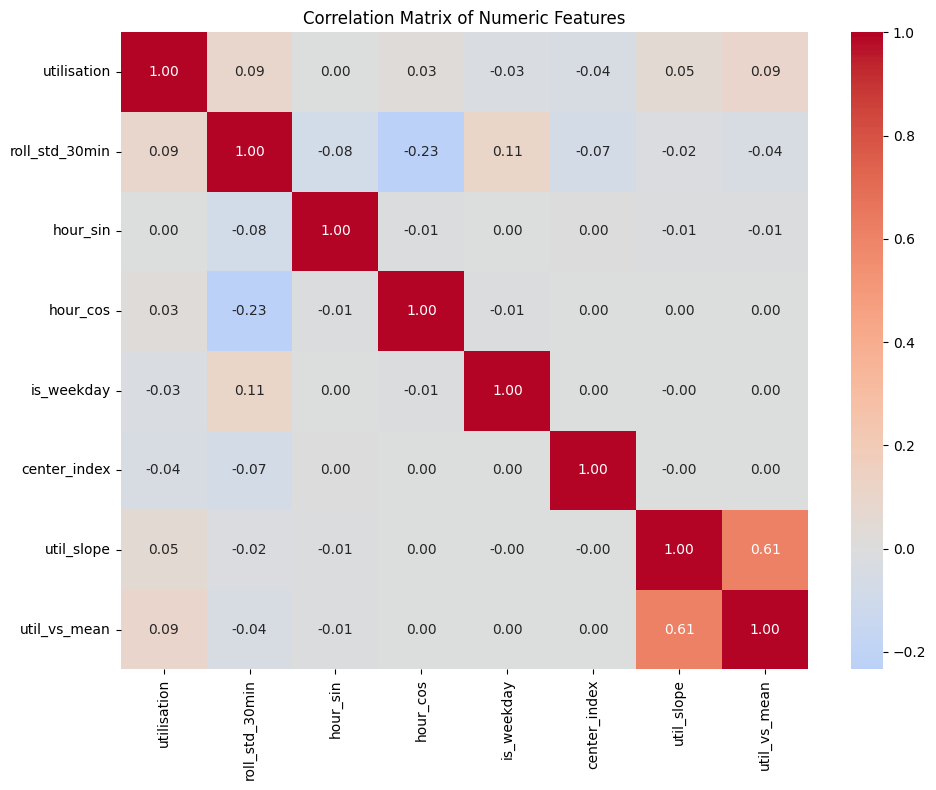

util_vs_mean    util_slope        0.610689
util_slope      util_vs_mean      0.610689
roll_std_30min  hour_cos          0.233955
hour_cos        roll_std_30min    0.233955
roll_std_30min  is_weekday        0.105008
is_weekday      roll_std_30min    0.105008
util_vs_mean    utilisation       0.094863
utilisation     util_vs_mean      0.094863
                roll_std_30min    0.091850
roll_std_30min  utilisation       0.091850
hour_sin        roll_std_30min    0.082432
roll_std_30min  hour_sin          0.082432
                center_index      0.073025
center_index    roll_std_30min    0.073025
util_slope      utilisation       0.054021
dtype: float64


In [21]:
numeric_features = [
    "utilisation",
    # "roll_mean_30min", #remove due to high correlation with utilisation
    "roll_std_30min",
    # "dock_ratio", #remove due to high correlation with utilisation
    # "hour_slot",
    "hour_sin", 
    "hour_cos",
    "is_weekday",
    "center_index",
    "util_slope",
    "util_vs_mean",
]

corr = df[numeric_features].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix of Numeric Features")
plt.tight_layout()
plt.show()


corr_pairs = corr.abs().unstack().sort_values(ascending=False)
corr_pairs = corr_pairs[corr_pairs < 1.0]

print(corr_pairs.head(15))

### 6.2 VIF on sampled encoded feature matrix

In [22]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd
import numpy as np

# Use the encoded feature matrix already prepared for modelling
X_vif = X.copy()

# Remove missing values just in case
X_vif = X_vif.dropna().copy()

# Sample for speed
sample_size = min(50000, len(X_vif))
X_vif_sample = X_vif.sample(sample_size, random_state=42)

# Ensure numeric dtype
X_vif_sample = X_vif_sample.astype(float)

vif_data = pd.DataFrame()
vif_data["feature"] = X_vif_sample.columns
vif_data["VIF"] = [
    variance_inflation_factor(X_vif_sample.values, i)
    for i in range(X_vif_sample.shape[1])
]

vif_data = vif_data.sort_values("VIF", ascending=False)
vif_data.head(15)


# flag feature with high VIF
high_vif = vif_data[vif_data["VIF"] > 5].copy()
print("Features with VIF > 5:")
print(high_vif.to_string(index=False))

Features with VIF > 5:
Empty DataFrame
Columns: [feature, VIF]
Index: []


### VIF first run with all features:
`Features with VIF > 5:

feature:          VIF
-    utilisation:         inf
- roll_mean_30min:         inf
- util_vs_mean: 9.007199e+15
- center_index: 1.038968e+01
- dock_ratio: 8.105422e+00`

Variance Inflation Factor (VIF) analysis revealed perfect multicollinearity between utilisation, rolling mean, and deviation-from-mean features, due to a deterministic linear relationship. To resolve this, rolling mean was removed while retaining utilisation and deviation features, preserving interpretability and predictive information.
We also removed dock_ratio as complemenraty of utilisation.

### After removing dock_ratio and roll_mean_30min
Features with VIF > 5:
     feature      VIF
center_index 5.192763

which is acceptable.

## 7. Train/test split

In [23]:

# Time‑based split: last 120 days as test
cutoff = df['last_reported'].max() - pd.Timedelta(days=365)
train_mask = df['last_reported'] < cutoff

X_train, X_test = X[train_mask], X[~train_mask]


## 8. Scaling

In [24]:

# Scale features (except one‑hot)
scaler = StandardScaler(with_mean=False)
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


print("Train shape:", X_train_scaled.shape, "Test shape:", X_test_scaled.shape)

Train shape: (6727191, 11) Test shape: (6782627, 11)



## 9. Logistic model (empty stations)

In [25]:
RANDOM_SEED = 42
y = df["empty_in_30min"]
y_train, y_test = df["empty_in_30min"][train_mask], df["empty_in_30min"][~train_mask]

model_empty = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_SEED)
model_empty.fit(X_train_scaled, y_train)

y_pred = model_empty.predict(X_test_scaled)
y_proba = model_empty.predict_proba(X_test_scaled)[:, 1]

print(f'Classification Report:\n{classification_report(y_test, y_pred)}')
print(f"ROC AUC: {roc_auc_score(y_test, y_proba)}")

cm = confusion_matrix(y_test, y_pred)
print(f'Confusion Matrix:\n{cm}')


f1_macro = f1_score(y_test, y_pred, average="macro")
print(f"Macro F1: {f1_macro}")

roc_auc = roc_auc_score(y_test, y_proba)
print("ROC AUC:", roc_auc)

Classification Report:
              precision    recall  f1-score   support

       False       0.99      0.86      0.92   5734721
        True       0.56      0.96      0.71   1047906

    accuracy                           0.88   6782627
   macro avg       0.77      0.91      0.81   6782627
weighted avg       0.93      0.88      0.89   6782627

ROC AUC: 0.9669812580637451
Confusion Matrix:
[[4929433  805288]
 [  37771 1010135]]
Macro F1: 0.8133952267960547
ROC AUC: 0.9669812580637451


## 10. Logistic model (full stations)

In [26]:
y = df["full_in_30min"]
y_train, y_test = df["full_in_30min"][train_mask], df["full_in_30min"][~train_mask]
model_full = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_SEED)
model_full.fit(X_train_scaled, y_train)



y_pred = model_full.predict(X_test_scaled)
y_proba = model_full.predict_proba(X_test_scaled)[:, 1]

print(f'Classification Report:\n{classification_report(y_test, y_pred)}')
print(f"ROC AUC: {roc_auc_score(y_test, y_proba)}")

cm = confusion_matrix(y_test, y_pred)
print(f'Confusion Matrix:\n{cm}')


f1_macro = f1_score(y_test, y_pred, average="macro")
print(f"Macro F1: {f1_macro}")

roc_auc = roc_auc_score(y_test, y_proba)
print("ROC AUC:", roc_auc)

Classification Report:
              precision    recall  f1-score   support

       False       1.00      0.91      0.95   6432061
        True       0.37      0.97      0.54    350566

    accuracy                           0.91   6782627
   macro avg       0.68      0.94      0.74   6782627
weighted avg       0.97      0.91      0.93   6782627

ROC AUC: 0.980750948740643
Confusion Matrix:
[[5852987  579074]
 [   8914  341652]]
Macro F1: 0.744830233190599
ROC AUC: 0.980750948740643


## 11. Logistic model multimodal

In [27]:
y = df["band_30min"]
y_train, y_test = df["band_30min"][train_mask], df["band_30min"][~train_mask]
print(y_train.value_counts(normalize=True).sort_index())


log_reg = LogisticRegression(
    max_iter=200,
    solver='saga',
    tol=1e-3,
    verbose=1
)
log_reg.fit(X_train_scaled, y_train)

y_pred = log_reg.predict(X_test_scaled)
y_proba = log_reg.predict_proba(X_test_scaled)

print(classification_report(y_test, y_pred))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred, labels=band_labels))

band_30min
0    0.344124
1    0.219336
2    0.175558
3    0.124854
4    0.136128
Name: proportion, dtype: float64
Epoch 1, change: 1
Epoch 2, change: 0.50601107
Epoch 3, change: 0.049416032
Epoch 4, change: 0.020948146
Epoch 5, change: 0.0074466392
Epoch 6, change: 0.0027026031
convergence after 7 epochs took 50 seconds
              precision    recall  f1-score   support

           0       0.80      0.97      0.88   2393485
           1       0.59      0.53      0.56   1417633
           2       0.50      0.46      0.48   1150494
           3       0.40      0.02      0.04    858745
           4       0.61      0.93      0.73    962270

    accuracy                           0.67   6782627
   macro avg       0.58      0.58      0.54   6782627
weighted avg       0.63      0.67      0.62   6782627

Confusion matrix:
 [[2328770   52642    8489     506    3078]
 [ 542492  756163   94170    5528   19280]
 [  28027  443537  532002   14033  132895]
 [   5494   23754  383151   19593  426753

band labels: [0, 1, 2, 3, 4]


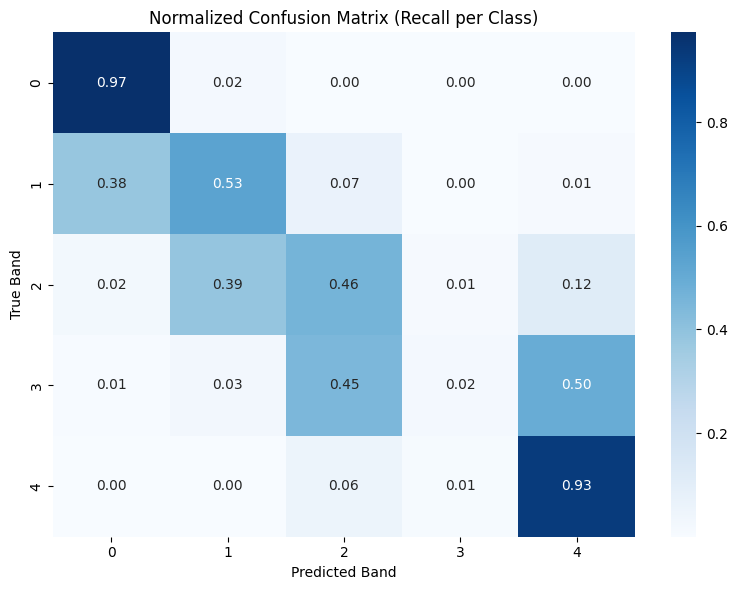

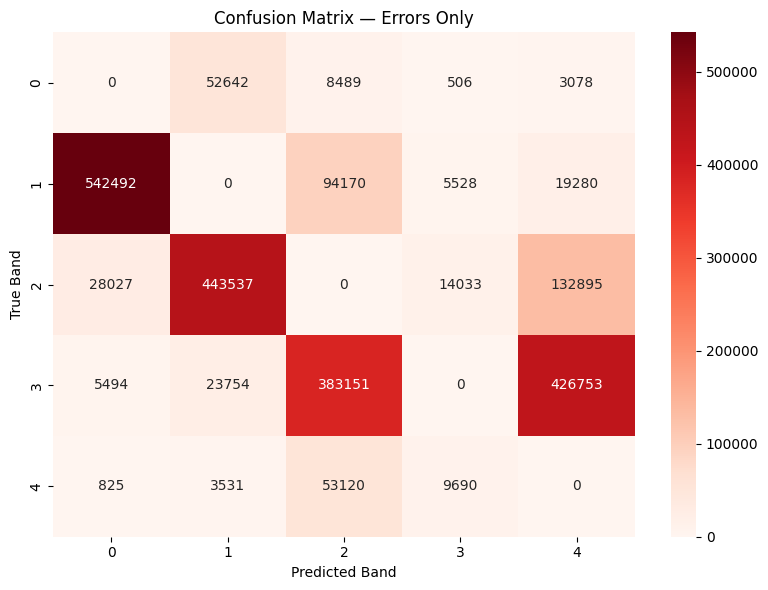

In [28]:
#Confusion matrix for the logistic regression model
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

cm = confusion_matrix(y_test, y_pred, labels=band_labels)
cm_norm = cm.astype('float') / cm.sum(axis=1, keepdims=True)
band_labels = [0, 1, 2, 3, 4]
print(f'band labels: {band_labels}')
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_norm,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=band_labels,
    yticklabels=band_labels
)
plt.title("Normalized Confusion Matrix (Recall per Class)")
plt.ylabel("True Band")
plt.xlabel("Predicted Band")
plt.tight_layout()
plt.show()



# Confusion matrix for highlligh errors
cm_errors = cm.copy()
np.fill_diagonal(cm_errors, 0)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_errors, annot=True, fmt='d', cmap='Reds',
            xticklabels=band_labels,
            yticklabels=band_labels)
plt.title("Confusion Matrix — Errors Only")
plt.ylabel("True Band")
plt.xlabel("Predicted Band")
plt.tight_layout()
plt.show()